<a href="https://colab.research.google.com/github/sahilmane69/Image-Pixel-Manipulator/blob/main/AIvsReal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Enviornment setup and database loading...

Dataset :- https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images

In [2]:
import os
from IPython.display import Image , display


### 1. Configure Kaggle Credentials


In [3]:
import os
from google.colab import userdata

# Securely load Kaggle credentials from Colab Secrets
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

### 2. Download and Unzip the CIFAKE Dataset

In [4]:
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images --unzip -p /content/cifake

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:00<00:00, 111MB/s] 



### 3. Verify the Downloaded Directory Structure

In [5]:
import os

dataset_path = '/content/cifake'
if os.path.exists(dataset_path):
    print("Dataset downloaded successfully!")
    print("Contents of root directory:", os.listdir(dataset_path))
    for root, dirs, files in os.walk(dataset_path):
        level = root.replace(dataset_path, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        for d in dirs[:2]:
            print(f"{subindent}{d}/")
        if files:
            print(f"{subindent}... containing {len(files)} files")
        break
else:
    print("Dataset path not found. Please verify your Kaggle API configuration and try again.")

Dataset downloaded successfully!
Contents of root directory: ['train', 'test']
cifake/
    train/
    test/


### 4. Visualize Sample Images from the CIFAKE Dataset
Let's plot some random samples of both "REAL" and "FAKE" (AI-generated) images to visually inspect them.

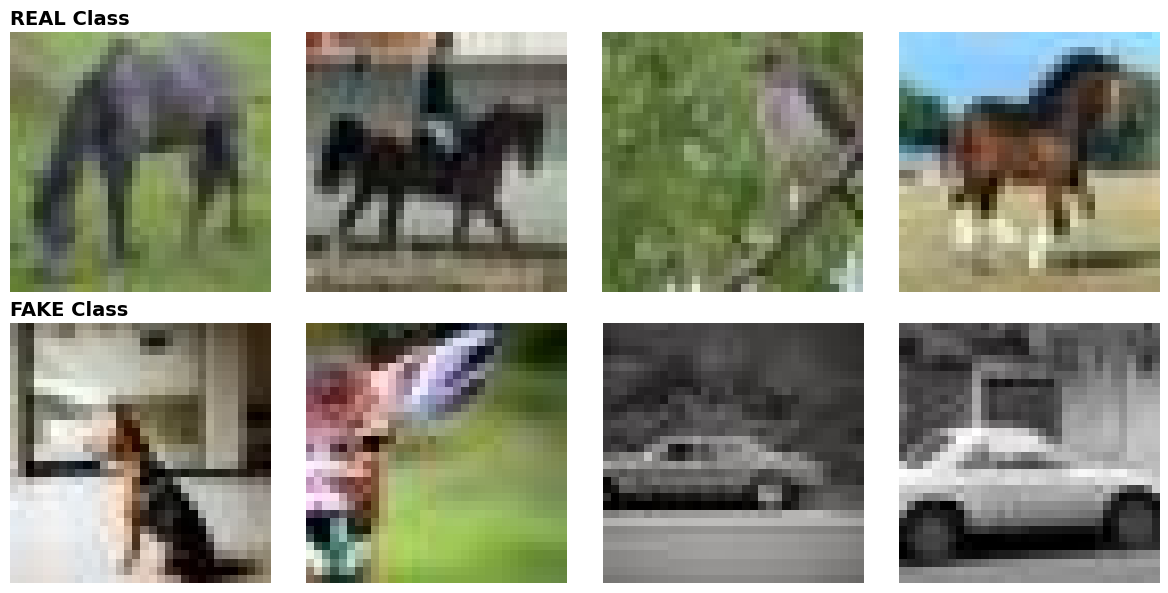

In [6]:
import matplotlib.pyplot as plt
import random
from PIL import Image

def plot_samples(base_path, subset='train', num_samples=4):
    classes = ['REAL', 'FAKE']
    fig, axes = plt.subplots(len(classes), num_samples, figsize=(12, 6))

    for i, cls in enumerate(classes):
        cls_dir = os.path.join(base_path, subset, cls)
        all_imgs = os.listdir(cls_dir)
        sampled_imgs = random.sample(all_imgs, num_samples)

        for j, img_name in enumerate(sampled_imgs):
            img_path = os.path.join(cls_dir, img_name)
            img = Image.open(img_path)

            ax = axes[i, j]
            ax.imshow(img)
            ax.axis('off')
            if j == 0:
                ax.set_title(f"{cls} Class", fontsize=14, loc='left', fontweight='bold')

    plt.tight_layout()
    plt.show()

plot_samples('/content/cifake')

### 5. Load and Preprocess Dataset
We will use TensorFlow/Keras to load the images dynamically from the directories and resize/scale them appropriately.

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

BATCH_SIZE = 64
IMG_SIZE = (32, 32)

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/cifake/train',
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    label_mode='binary'
)

# Load testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/cifake/test',
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    label_mode='binary'
)

# Prefetching and caching for optimized performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.


### 6. Define and Build the CNN Architecture
We design a simple yet powerful CNN model featuring convolution layers, batch normalization, max-pooling, and dropout to avoid overfitting.

In [8]:
model = models.Sequential([
    # Rescaling layer to normalize pixel values from [0, 255] to [0, 1]
    layers.Rescaling(1./255, input_shape=(32, 32, 3)),

    # First Convolutional block
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Second Convolutional block
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Third Convolutional block
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Classification head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')  # Binary output: 0 for Fake or 1 for Real
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           12

 Total params: 403,617 (1.54 MB)

 Trainable params: 402,721 (1.54 MB)

 Non-trainable params: 896 (3.50 KB)

### 7. Train the CNN Classifier
We train the model on the training dataset and validate on the test dataset, utilizing `EarlyStopping` to optimize training duration.

In [9]:
from tensorflow.keras.callbacks import EarlyStopping

# Configure early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train the model
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 804s 504ms/step - accuracy: 0.8942 - loss: 0.2576 - val_accuracy: 0.8870 - val_loss: 0.2747
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 773s 495ms/step - accuracy: 0.9319 - loss: 0.1743 - val_accuracy: 0.8883 - val_loss: 0.2837
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 793s 489ms/step - accuracy: 0.9398 - loss: 0.1568 - val_accuracy: 0.9305 - val_loss: 0.1829
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 762s 488ms/step - accuracy: 0.9445 - loss: 0.1445 - val_accuracy: 0.9428 - val_loss: 0.1435
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 770s 492ms/step - accuracy: 0.9493 - loss: 0.1328 - val_accuracy: 0.8817 - val_loss: 0.2768
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 797s 489ms/step - accuracy: 0.9516 - loss: 0.1262 - val_accuracy: 0.9456 - val_loss: 0.1386
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 766s 490ms/step - accuracy: 0.9554 - loss: 0.1164 - val_accuracy: 0.9012 - val_loss: 0.2480
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 771s 493ms/step - ac

### 8. Evaluate and Plot Loss/Accuracy History

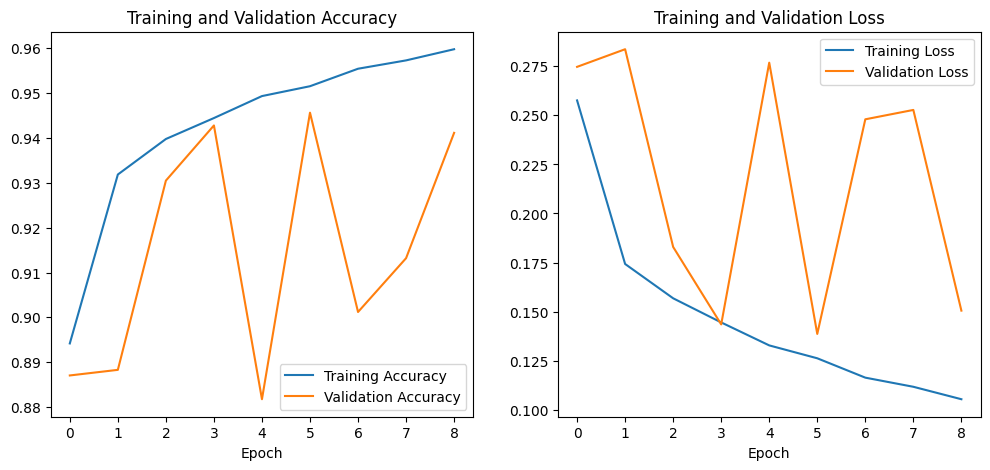

In [10]:
def plot_training_curves(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')

    plt.show()

plot_training_curves(history)

### 7. Train the CNN Classifier
We use the training dataset and validate on the test dataset. We also employ `EarlyStopping` to prevent overfitting if the performance plateaus.

In [11]:
from tensorflow.keras.callbacks import EarlyStopping

# Configure early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train the model
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 765s 489ms/step - accuracy: 0.9541 - loss: 0.1211 - val_accuracy: 0.9297 - val_loss: 0.1788
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 766s 490ms/step - accuracy: 0.9581 - loss: 0.1105 - val_accuracy: 0.9481 - val_loss: 0.1344
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 769s 492ms/step - accuracy: 0.9608 - loss: 0.1051 - val_accuracy: 0.9571 - val_loss: 0.1132
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 804s 493ms/step - accuracy: 0.9617 - loss: 0.1002 - val_accuracy: 0.9499 - val_loss: 0.1392
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 771s 493ms/step - accuracy: 0.9648 - loss: 0.0944 - val_accuracy: 0.9596 - val_loss: 0.1070
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 769s 492ms/step - accuracy: 0.9652 - loss: 0.0917 - val_accuracy: 0.9588 - val_loss: 0.1134
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 767s 491ms/step - accuracy: 0.9666 - loss: 0.0883 - val_accuracy: 0.9541 - val_loss: 0.1337
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 803s 492ms/step - ac

### 8. Evaluate and Plot Loss/Accuracy History

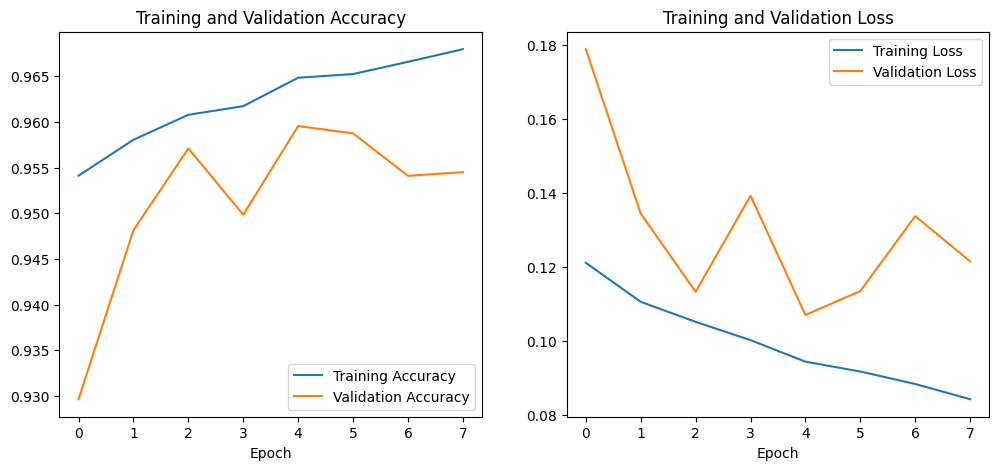

In [12]:
def plot_training_curves(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')

    plt.show()

plot_training_curves(history)

### 9. Evaluate Performance with a Confusion Matrix & Classification Report
Let's evaluate the model on the full test dataset and visualize its classification performance across both categories.

Test Loss: 0.1070
Test Accuracy: 0.9596

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.96      0.95      0.96     10000
        REAL       0.95      0.96      0.96     10000

    accuracy                           0.96     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.96      0.96      0.96     20000



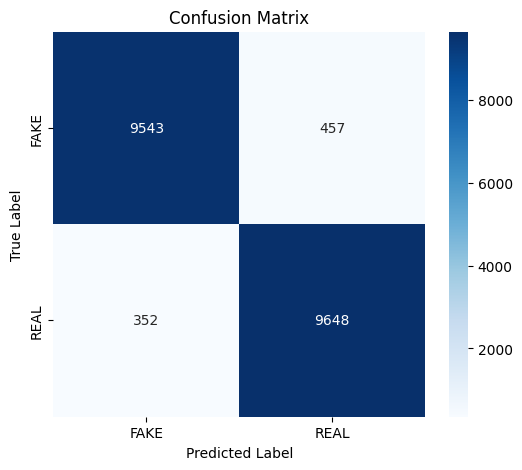

In [13]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Evaluate on test set
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}\n")

# 2. Get predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(preds)
    y_true.extend(labels.numpy())

y_pred_binary = (np.array(y_pred) > 0.5).astype(int)
y_true = np.array(y_true).astype(int)

# 3. Print Classification Report
classes = ['FAKE', 'REAL']
print("Classification Report:")
print(classification_report(y_true, y_pred_binary, target_names=classes))

# 4. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### 10. Test with Your Own Image
Upload an image from your computer to see if the trained model classifies it as REAL or FAKE.

Saving wp13232029-batman-mac-wallpapers.jpg to wp13232029-batman-mac-wallpapers.jpg


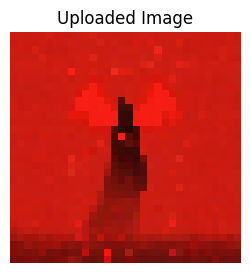

Prediction: REAL
Confidence: 93.48%

*Note: This prediction is generated by an AI model trained on the CIFAKE dataset. It represents an algorithmic estimation and should not be used as absolute proof of the image's actual origin.*


In [15]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
import io

try:
    uploaded = files.upload()
    for fn in uploaded.keys():
        img_data = uploaded[fn]
        img = image.load_img(io.BytesIO(img_data), target_size=(32, 32))

        plt.figure(figsize=(3, 3))
        plt.imshow(img)
        plt.axis('off')
        plt.title("Uploaded Image")
        plt.show()

        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)

        prediction = model.predict(img_array, verbose=0)[0][0]

        if prediction > 0.5:
            label = "REAL"
            confidence = prediction * 100
        else:
            label = "FAKE"
            confidence = (1 - prediction) * 100

        print(f"Prediction: {label}")
        print(f"Confidence: {confidence:.2f}%")
        print("\n*Note: This prediction is generated by an AI model trained on the CIFAKE dataset. It represents an algorithmic estimation and should not be used as absolute proof of the image's actual origin.*")
except Exception as e:
    print(f"An error occurred while processing the image: {e}")